In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

In [2]:
df = pd.read_parquet("../data/juegos_steam.parquet")

En el Analisis Bivariante (aunque sigamos en el) hemos visto que enero es, posiblemente, el mejor mes.

Pero vamos a ver si es cierto, o es simplemente una casualidad.

In [3]:
# Primero vamos a sacar una columna con la cantidad
# de juegos que superan los 20k, para descartarnos los de 0

# Para ello, calculamos el valor "medio" de owners
df["media_owners"] = (df["estimated_owners_min"] + df["estimated_owners_max"]) / 2

df["mas_10k"] = (df["media_owners"] > 10000)

df["mas_10k"]


0         False
1          True
3         False
4         False
5         False
          ...  
144258     True
144264    False
144309    False
144324     True
144332    False
Name: mas_10k, Length: 41677, dtype: bool

In [4]:
# Esto ya nos da una idea, pero lo voy a dividir por años
# para mejor uso mas tarde

df["year"] = pd.to_datetime(df["release_date"]).dt.year

df.groupby("year")["mas_10k"].agg(cantidad="size")

,cantidad
year,
2023,11633
2024,15436
2025,14608


In [5]:
# Ahora vamos a hacer una tabla de porcentaje de exito
# para poder representarla, usando la media

tabla_porcentaje = df.pivot_table(index="month", columns="year", values="mas_10k", aggfunc="mean") * 100

tabla_porcentaje

year,2023,2024,2025
month,,,
1,24.094881,18.441815,12.946783
2,19.596865,16.572352,10.365336
3,20.591133,14.346712,9.608091
4,19.871795,15.264527,11.678366
5,18.697479,15.045593,10.855950
6,18.506132,12.739965,2.815622
7,19.189765,14.296998,1.955782
8,19.132150,13.680297,2.090909
9,19.736842,15.095847,2.842640


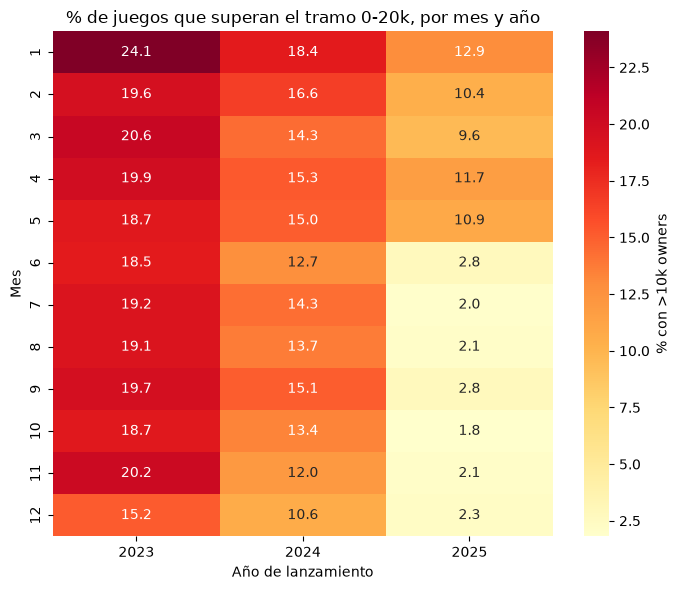

In [6]:
# Adelante, grafico!
plt.figure(figsize=(7, 6))
sns.heatmap(tabla_porcentaje, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% con >10k owners"})
plt.title("% de juegos que superan el tramo 0-20k, por mes y año")
plt.xlabel("Año de lanzamiento") 
plt.ylabel("Mes")
plt.tight_layout() 
plt.show()

A simple vista, Enero sigue saliendo victorioso. Pero me gustaria comprobarlo (si es real o casualidad)

Por lo que hay 2 hipotesis: O no tiene nada que ver el mes con el exito, o, Enero SI es clave.

In [7]:
# Para ello, voy a usar la chi_contingency

# Voy a guardarme los resultados, por si acaso.
resultados = []
# recorro los datos para poder guardar los datos
for i in [2023, 2024, 2025]:
    datos = df[df["year"] == i].copy() # Para evitar borrar los datos
    datos["grupo"] = np.where(datos["month"] == 1, "Enero", "Resto") # Asi puesto para diferenciar si es Enero o no

    # Ahora si, vamos a hacer la contingencia chi2 (?) (Tremenda traduccion acabo de poner)
    pvalor_mes = chi2_contingency(pd.crosstab(datos["month"], datos["mas_10k"]))[1]

    print("Año:", i, ", pvalor:", pvalor_mes)

    # Vamos con la hipotesis numero 2

    datos2 = pd.crosstab(datos["grupo"], datos["mas_10k"])
    
    # Como chi2_contingency devuelve un objeto, lo guardo para sacar sus resultados
    contingency_datos = chi2_contingency(datos2)

    resultado = contingency_datos[0]
    pvalor_chi2 = contingency_datos[1]
    frecuencia_esperada = contingency_datos[3]

    print("----")
    print("chi2: ", resultado)
    print("pvalor de la contingencia:", pvalor_chi2)
    print("frecuencia minima esperada:", frecuencia_esperada.min())
    print("-----")

    # Y ahora vamos a ver si Enero es el mejor mes para conseguir compradores
    # Para ello sacamos la media

    porcentaje = datos.groupby("grupo")["mas_10k"].mean() * 100

    print("Porcentaje en Enero:", porcentaje["Enero"])
    print("Porcentaje el resto de meses:", porcentaje["Resto"],"\n")

    resultados.append({"año": i,
                        "Enero": porcentaje["Enero"],
                        "Resto": porcentaje["Resto"],
                        "pvalor": pvalor_chi2})



Año: 2023 , pvalor: 0.008101216631374326
----
chi2:  11.844343340108429
pvalor de la contingencia: 0.0005783676699514764
frecuencia minima esperada: 155.33877761540444
-----
Porcentaje en Enero: 24.094881398252184
Porcentaje el resto de meses: 19.04542097488922 

Año: 2024 , pvalor: 1.7847828017333603e-06
----
chi2:  16.257439346221453
pvalor de la contingencia: 5.529206488341287e-05
frecuencia minima esperada: 143.27118424462296
-----
Porcentaje en Enero: 18.441814595660748
Porcentaje el resto de meses: 13.826099015393151 

Año: 2025 , pvalor: 2.0389773632799375e-96
----
chi2:  93.79315128898885
pvalor de la contingencia: 3.502817500695384e-22
frecuencia minima esperada: 81.6178121577218
-----
Porcentaje en Enero: 12.946783161239079
Porcentaje el resto de meses: 5.873099108547457 



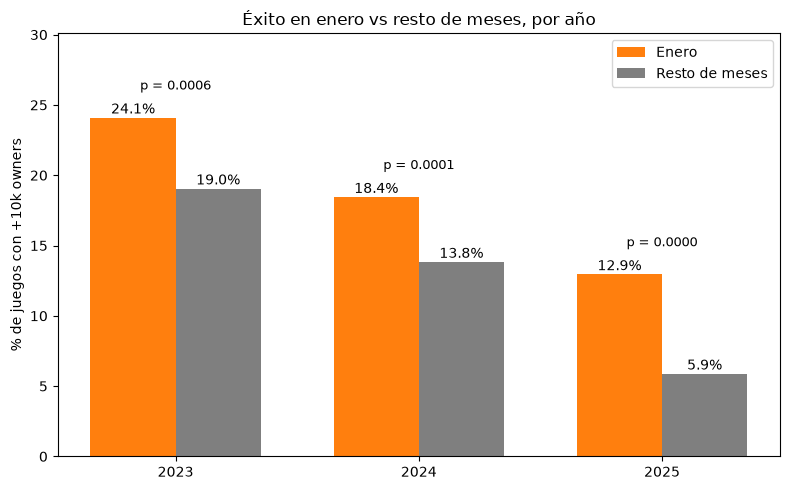

In [8]:
# Vamos a representarlo en una grafica bien bonita
# Para ello, vamos a usar la lista (diccionario) que guardamos antes.

df_resultados = pd.DataFrame(resultados)
x = np.arange(len(resultados)) # Para la X creo la lista desde 0 hasta el tamaño
ancho = 0.35

# Grafico go go go
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho/2, df_resultados["Enero"], ancho, label="Enero", color="tab:orange")
ax.bar(x + ancho/2, df_resultados["Resto"], ancho, label="Resto de meses", color="tab:gray")

for j, fila in df_resultados.iterrows():
    ax.text(j - ancho/2, fila["Enero"] + 0.3, f"{fila['Enero']:.1f}%", ha="center")
    ax.text(j + ancho/2, fila["Resto"] + 0.3, f"{fila['Resto']:.1f}%", ha="center")
    ax.text(j, max(fila["Enero"], fila["Resto"]) + 2, f"p = {fila['pvalor']:.4f}", ha="center", fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(df_resultados["año"])
ax.set_ylabel("% de juegos con +10k owners")
ax.set_title("Éxito en enero vs resto de meses, por año")
ax.set_ylim(0, df_resultados[["Enero", "Resto"]].max().max() + 6)
ax.legend()
plt.tight_layout()
plt.show()

Al ser los p-valores menores de 0,05, se comprueba que efectivamente, el mes de lanzamiento si que tiene que ver, Y, que, por tanto, Enero es el mejor mes.

Y ahora, vamos a sacar que Genero es el que (posiblemente) mas exito tiene.

In [9]:
columnas_generos = [f"genre_{i}" for i in range(11)]
largo = (df
         .melt(id_vars=["year", "month", "mas_10k"], value_vars=columnas_generos, value_name="genero")
         .query("genero != 'Desconocido'"))

resumen = (largo.groupby("genero")["mas_10k"].agg(n="size", porcentaje_exito="mean")
           .assign(porcentaje_exito=lambda t: 100 * t["porcentaje_exito"]) # lo convierto a tanto por 100
           .sort_values("n", ascending=False).head(10))
print("Media global 2023-2025:", round(100 * df["mas_10k"].mean(), 1), "%")

Media global 2023-2025: 12.9 %


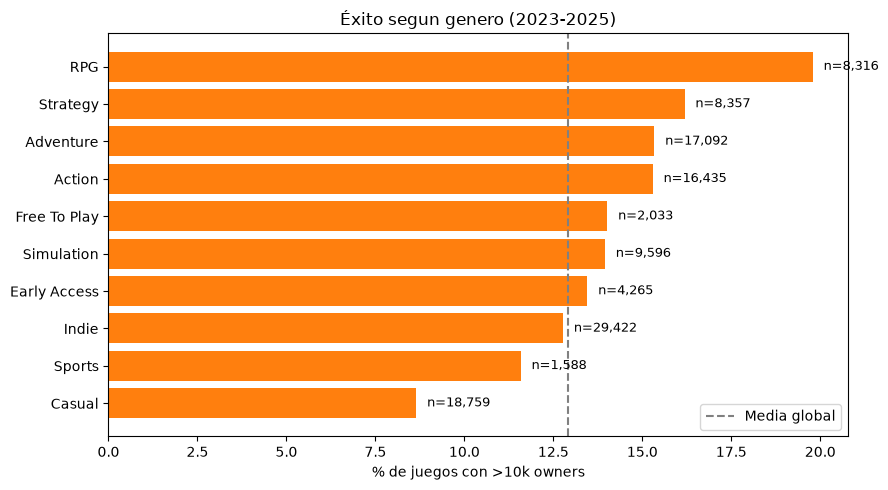

In [10]:
orden = resumen.sort_values("porcentaje_exito").index
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(orden, resumen.loc[orden, "porcentaje_exito"], color="tab:orange")
for i, g in enumerate(orden):
    ax.text(resumen.loc[g, "porcentaje_exito"] + 0.3, i, f"n={resumen.loc[g, 'n']:,}", va="center", fontsize=9)
ax.axvline(100 * df["mas_10k"].mean(), color="gray", linestyle="--", label="Media global")
ax.set_xlabel("% de juegos con >10k owners"); ax.set_title("Éxito segun genero (2023-2025)")
ax.legend()
plt.tight_layout()
plt.show()

Efectivamente, RPG es el que mas porcentaje de exito tiene.